# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
import random

numbers = list(range(10))  # список для shuffle

# Двічі ДО set_seed()
print("=== ДО set_seed() ===")

print("Випадкове число 1:", random.randint(1, 100))
random.shuffle(numbers)
print("Перемішаний список 1:", numbers)

print("Випадкове число 2:", random.randint(1, 100))
random.shuffle(numbers)
print("Перемішаний список 2:", numbers)


# Фіксуємо seed
set_seed()
print("\nSeed зафіксовано:", SEED)


# Двічі ПІСЛЯ set_seed(), з повторним викликом перед кожною генерацією
print("\n=== ПІСЛЯ set_seed() з повторним викликом ===")

set_seed()
print("Випадкове число 1:", random.randint(1, 100))

set_seed()
print("Випадкове число 2:", random.randint(1, 100))


# Двічі БЕЗ проміжного виклику set_seed()
print("\n=== БЕЗ проміжного set_seed() ===")

print("Випадкове число 1:", random.randint(1, 100))
print("Випадкове число 2:", random.randint(1, 100))

# Перевіряємо shuffle за тим самим принципом
numbers = list(range(10))

set_seed()
random.shuffle(numbers)
print("Перемішаний список 1:", numbers)

random.shuffle(numbers)
print("Перемішаний список 2:", numbers)


=== ДО set_seed() ===
Випадкове число 1: 27
Перемішаний список 1: [7, 9, 1, 5, 3, 8, 6, 0, 4, 2]
Випадкове число 2: 74
Перемішаний список 2: [2, 3, 5, 1, 6, 0, 4, 9, 8, 7]

Seed зафіксовано: 42

=== ПІСЛЯ set_seed() з повторним викликом ===
Випадкове число 1: 82
Випадкове число 2: 82

=== БЕЗ проміжного set_seed() ===
Випадкове число 1: 15
Випадкове число 2: 4
Перемішаний список 1: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Перемішаний список 2: [8, 6, 2, 5, 3, 0, 4, 7, 9, 1]


До виклику `set_seed()` генератор випадкових чисел працює без зафіксованого початкового стану, тому під час повторних запусків результати можуть відрізнятися. Функція `random.randint(1, 100)` генерує випадкове ціле число від 1 до 100, а `random.shuffle()` змінює порядок елементів списку.

Після виклику `set_seed()` генератор отримує певний початковий стан. Якщо перед кожною генерацією повторно викликати `set_seed()` з однаковим значенням `SEED`, то результати відповідних операцій будуть повторюватися. Наприклад, двічі згенеровані таким способом випадкові числа будуть однаковими, як і результати перемішування однакового списку.

Якщо ж викликати `set_seed()` лише один раз, а потім генерувати числа або перемішувати список без повторного встановлення початкового стану, генератор продовжуватиме свою послідовність. Тому наступні результати можуть відрізнятися один від одного.

Отже, `set_seed()` використовується для відтворюваності результатів: це дає змогу отримувати ту саму послідовність псевдовипадкових значень під час повторних запусків за однакових умов.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
import numpy as np

zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("Масив із нулів:")
print(zeros_arr)
print("Форма:", zeros_arr.shape)
print("Тип даних:", zeros_arr.dtype)

print("\nМасив із сімок:")
print(sevens_arr)
print("Форма:", sevens_arr.shape)
print("Тип даних:", sevens_arr.dtype)


Масив із нулів:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Форма: (3, 4)
Тип даних: float64

Масив із сімок:
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]]
Форма: (3, 4)
Тип даних: int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
import numpy as np

arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print("Масив np.arange:")
print(arange_arr)

print("\nМасив np.linspace:")
print(linspace_arr)


Масив np.arange:
[ 0  2  4  6  8 10 12 14 16 18]

Масив np.linspace:
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
import numpy as np

identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Одинична матриця 4×4:")
print(identity)
print("Кількість вимірів:", identity.ndim)

print("\nВипадковий масив 3×3:")
print(random_ints)
print("Кількість вимірів:", random_ints.ndim)


Одинична матриця 4×4:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Кількість вимірів: 2

Випадковий масив 3×3:
[[6 3 7]
 [4 6 9]
 [2 6 7]]
Кількість вимірів: 2


За допомогою функції np.eye(4) створено одиничну матрицю розміром 4×4. Вона містить одиниці на головній діагоналі та нулі в усіх інших позиціях.

Функція np.random.randint(0, 10, size=(3, 3)) створює масив розміром 3×3 із випадковими цілими числами в діапазоні від 0 до 9. Число 10 не включається до діапазону.

Атрибут .ndim показує кількість вимірів масиву. Для обох масивів результат дорівнює 2, оскільки вони є двовимірними та складаються з рядків і стовпців.

**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
import numpy as np

scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = np.mean(scores)
std = np.std(scores)

z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
import numpy as np

arr = np.arange(1, 13)

# Перетворюємо 1D масив на матрицю 3×4
matrix = arr.reshape(3, 4)

# Обчислюємо суми по рядках і стовпцях
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
import pandas as pd

df = pd.DataFrame({
    "student": ["Анна", "Іван", "Марія", "Олег", "Софія", "Андрій"],
    "score": [85, 72, 96, 80, 91, 78]
})

# Відбираємо студентів з оцінками понад 80
# і сортуємо за спаданням оцінки
top = df[df["score"] > 80].sort_values(by="score", ascending=False)

print(top)


  student  score
2   Марія     96
4   Софія     91
0    Анна     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
import numpy as np

df["grade"] = np.where(
    df["score"] >= 90, "A",
    np.where(df["score"] >= 75, "B", "C")
)

print(df)


  student  score grade
0    Анна     85     B
1    Іван     72     C
2   Марія     96     A
3    Олег     80     B
4   Софія     91     A
5  Андрій     78     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
import torch

# Створюємо тензор із нулів і тензор із сімок
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print("Тензор із нулів:")
print(zeros_t)
print("Форма:", zeros_t.shape)
print("Тип даних:", zeros_t.dtype)

print("\nТензор із сімок:")
print(sevens_t)
print("Форма:", sevens_t.shape)
print("Тип даних:", sevens_t.dtype)


Тензор із нулів:
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Форма: torch.Size([2, 3])
Тип даних: torch.float32

Тензор із сімок:
tensor([[7, 7, 7],
        [7, 7, 7]])
Форма: torch.Size([2, 3])
Тип даних: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
import torch

# Тензор від 0 до 20 із кроком 2
arange_t = torch.arange(0, 20, 2)

# Тензор із 5 рівномірно розподілених точок від 0 до 1
linspace_t = torch.linspace(0, 1, 5)

print("Тензор torch.arange:")
print(arange_t)

print("\nТензор torch.linspace:")
print(linspace_t)


Тензор torch.arange:
tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

Тензор torch.linspace:
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
import torch

# Створюємо тензор зі списку
from_list = torch.tensor([[1, 2], [3, 4]])

# Створюємо випадковий тензор форми 3×3
random_t = torch.rand(3, 3)

print("Тензор зі списку:")
print(from_list)
print("Форма:", from_list.shape)
print("Тип даних:", from_list.dtype)
print("Кількість вимірів:", from_list.ndim)

print("\nВипадковий тензор:")
print(random_t)
print("Форма:", random_t.shape)
print("Тип даних:", random_t.dtype)
print("Кількість вимірів:", random_t.ndim)


Тензор зі списку:
tensor([[1, 2],
        [3, 4]])
Форма: torch.Size([2, 2])
Тип даних: torch.int64
Кількість вимірів: 2

Випадковий тензор:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
Форма: torch.Size([3, 3])
Тип даних: torch.float32
Кількість вимірів: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
import torch

n = 5.0

# Створюємо тензор із можливістю обчислення градієнта
x = torch.tensor(n, requires_grad=True)

# Обчислюємо функцію
y = x ** 2

# Обчислюємо градієнт автоматично
y.backward()

# Порівнюємо автоматичний та аналітичний градієнти
print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)
# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n


Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


За допомогою torch.tensor(n, requires_grad=True) створено тензор зі значенням 5, для якого PyTorch автоматично відстежує операції, необхідні для обчислення градієнта.

Далі обчислено y = x ** 2, тобто квадрат значення x. Метод y.backward() запускає автоматичне диференціювання та обчислює градієнт функції за змінною x.

Аналітично похідна функції (y=x^2) дорівнює (dy/dx=2x). При (x=5) її значення становить 10.

Результат x.grad.item() також дорівнює 10. Отже, автоматично обчислений градієнт PyTorch збігається з аналітичним результатом.

**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
import torch
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1
for i in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()
# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


Створено параметр `x` зі значенням 0.0 та `requires_grad=True`, щоб PyTorch міг обчислювати його градієнт.

Функція втрат має вигляд `(x - 3) ** 2 + 5`. За допомогою `loss.backward()` обчислюється градієнт, після чого значення `x` оновлюється у напрямку його зменшення. Операції оновлення виконуються в блоці `torch.no_grad()`, а `x.grad.zero_()` обнуляє градієнт перед наступним кроком.

Після 20 ітерацій значення `x` наближається до 3 — точки мінімуму функції.

### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

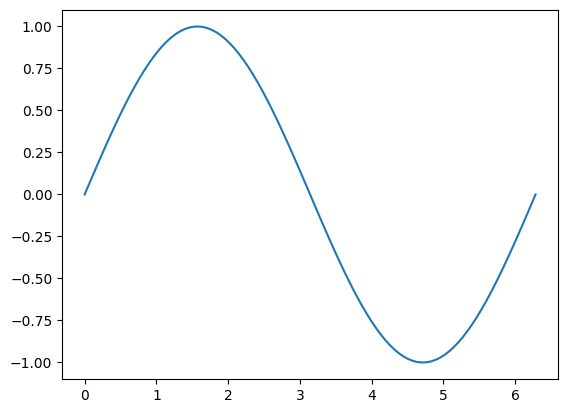

In [19]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
import numpy as np
import matplotlib.pyplot as plt

xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

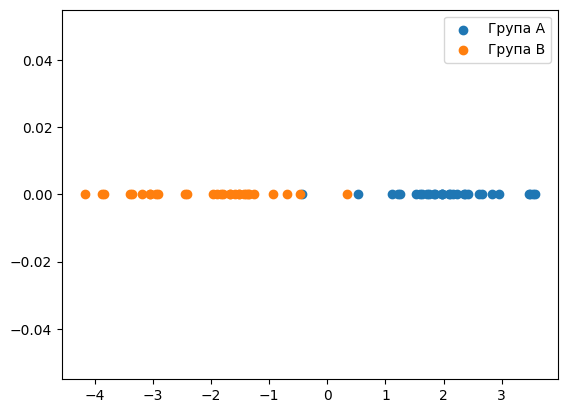

In [20]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2
plt.scatter(group_a, np.zeros(30), color="C0", label="Група A")
plt.scatter(group_b, np.zeros(30), color="C1", label="Група B")

plt.legend()
plt.show()
# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

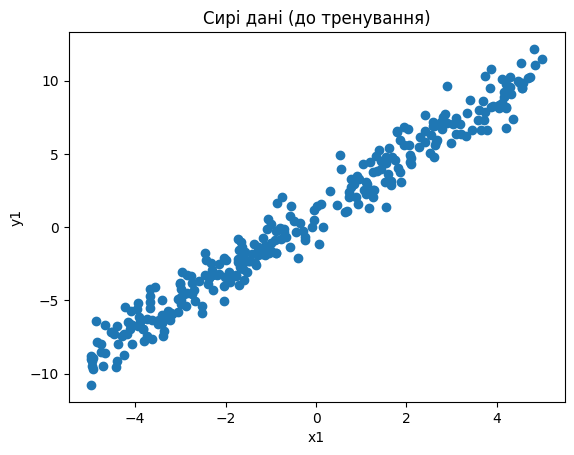

In [22]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
indices = torch.randperm(TASK1_N)

# Перемішуємо дані
x1 = x1[indices]
y1 = y1[indices]

# Визначаємо межі вибірок
train_end = int(TASK1_N * 0.7)
val_end = int(TASK1_N * 0.85)

# Розділяємо дані
x_train1, y_train1 = x1[:train_end], y1[:train_end]
x_val1, y_val1 = x1[train_end:val_end], y1[train_end:val_end]
x_test1, y_test1 = x1[val_end:], y1[val_end:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


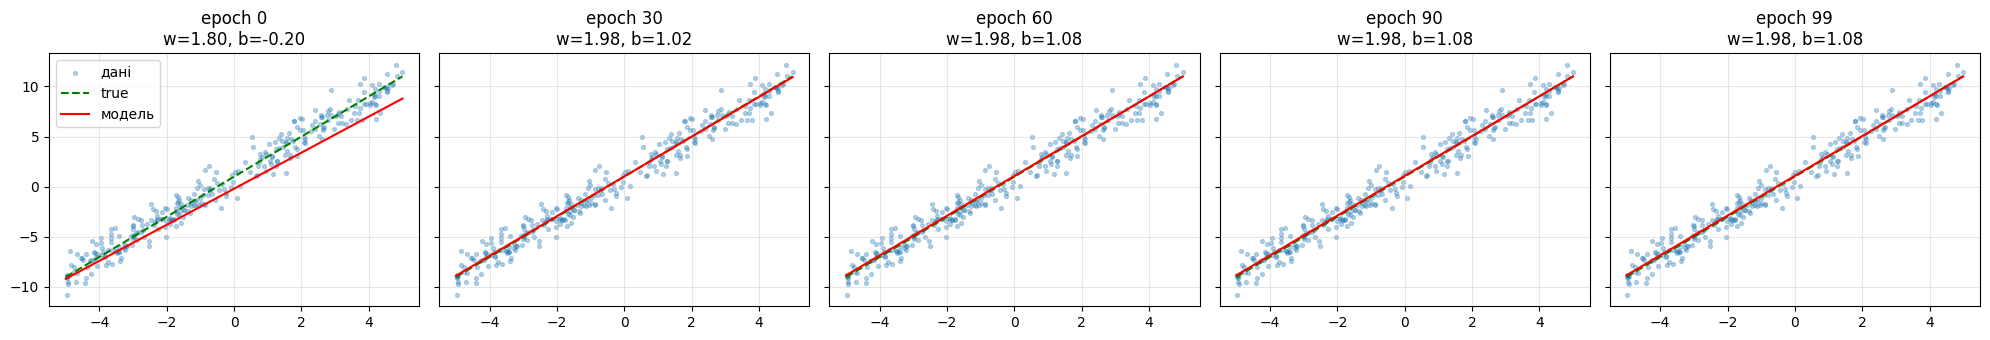

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Вправа 20. Лінійна регресія: залежність результату тесту від часу підготовки

Для власного сценарію обрано залежність результату тесту від кількості годин, витрачених на підготовку. Припускається, що зі збільшенням часу навчання результат тесту в середньому покращується.

Залежність описується формулою \(y = wx + b + \varepsilon\), де \(x\) — кількість годин підготовки, \(y\) — результат тесту в балах, \(w = 6\) — середнє збільшення результату на 6 балів за додаткову годину підготовки, \(b = 30\) — умовний базовий результат, а \(\varepsilon\) — випадковий шум зі стандартним відхиленням 5.

Такі значення є умовними, але правдоподібними для навчального прикладу. Випадковий шум враховує вплив інших чинників, зокрема попередніх знань і складності тесту.

На основі згенерованих даних буде створено CSV-файл, виконано поділ даних на навчальну, валідаційну та тестову вибірки, навчено модель лінійної регресії та перевірено її якість на тестовій вибірці. Основні етапи реалізуються у вигляді окремих функцій для повторного використання.

In [26]:
# Параметри нашого сценарію
TASK20_TRUE_W = 6.0
TASK20_TRUE_B = 30.0
TASK20_N = 300

# Генеруємо дані з випадковим шумом
x20 = torch.empty(TASK20_N, 1).uniform_(0, 10)
noise20 = 5.0 * torch.randn(TASK20_N, 1)
y20 = TASK20_TRUE_W * x20 + TASK20_TRUE_B + noise20

# Зберігаємо дані у CSV
import pandas as pd

df20 = pd.DataFrame({
    "hours": x20.numpy().flatten(),
    "score": y20.numpy().flatten()
})

df20.to_csv("study_data.csv", index=False)

print("Дані згенеровано та збережено у study_data.csv")
print(df20.head())

Дані згенеровано та збережено у study_data.csv
      hours      score
0  3.424041  58.990578
1  8.016564  74.950790
2  3.161734  43.563347
3  4.570613  55.321083
4  9.668693  80.244415


In [27]:
def split_data(x, y, train_ratio=0.7, val_ratio=0.15):
    # Випадково перемішуємо індекси
    indices = torch.randperm(len(x))

    # Визначаємо межі вибірок
    train_end = int(len(x) * train_ratio)
    val_end = int(len(x) * (train_ratio + val_ratio))

    # Розділяємо індекси
    train_idx = indices[:train_end]
    val_idx = indices[train_end:val_end]
    test_idx = indices[val_end:]

    # Повертаємо три набори даних
    return (
        x[train_idx], y[train_idx],
        x[val_idx], y[val_idx],
        x[test_idx], y[test_idx]
    )


# Розділяємо згенеровані дані
x20_train, y20_train, x20_val, y20_val, x20_test, y20_test = split_data(
    x20, y20
)

print(
    f"Train/Val/Test: "
    f"{len(x20_train)}/{len(x20_val)}/{len(x20_test)}"
)

Train/Val/Test: 210/45/45


In [28]:
# Створюємо модель лінійної регресії
def create_model():
    return torch.nn.Linear(1, 1)


# Функція навчання моделі
def train_model(model, x_train, y_train, x_val, y_val, epochs=300):
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        # Навчання
        model.train()

        predictions = model(x_train)
        loss = loss_fn(predictions, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Перевірка на валідаційній вибірці
        model.eval()

        with torch.no_grad():
            val_predictions = model(x_val)
            val_loss = loss_fn(val_predictions, y_val)

        if (epoch + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"Train Loss = {loss.item():.2f}, "
                f"Val Loss = {val_loss.item():.2f}"
            )

    return model


# Створюємо та навчаємо модель
model20 = create_model()

model20 = train_model(
    model20,
    x20_train, y20_train,
    x20_val, y20_val
)

Epoch 50: Train Loss = 3001.98, Val Loss = 3141.26
Epoch 100: Train Loss = 2674.62, Val Loss = 2784.28
Epoch 150: Train Loss = 2376.26, Val Loss = 2459.87
Epoch 200: Train Loss = 2105.27, Val Loss = 2166.14
Epoch 250: Train Loss = 1859.99, Val Loss = 1901.20
Epoch 300: Train Loss = 1638.82, Val Loss = 1663.22


In [29]:
# Функція оцінювання моделі на тестових даних
def evaluate_model(model, x_test, y_test):
    model.eval()

    with torch.no_grad():
        predictions = model(x_test)

        mse = torch.nn.MSELoss()(predictions, y_test)
        mae = torch.nn.L1Loss()(predictions, y_test)

    print(f"Середня квадратична помилка (MSE): {mse.item():.2f}")
    print(f"Середня абсолютна помилка (MAE): {mae.item():.2f}")


# Перевіряємо модель на тестовій вибірці
evaluate_model(model20, x20_test, y20_test)

# Порівнюємо справжні параметри з навченими
print("\nСправжні параметри:")
print(f"w = {TASK20_TRUE_W}, b = {TASK20_TRUE_B}")

print("\nПараметри навченої моделі:")
print(f"w = {model20.weight.item():.2f}")
print(f"b = {model20.bias.item():.2f}")

Середня квадратична помилка (MSE): 1541.36
Середня абсолютна помилка (MAE): 38.28

Справжні параметри:
w = 6.0, b = 30.0

Параметри навченої моделі:
w = 3.44
b = 3.35


In [30]:
# Повторно навчаємо модель із меншою швидкістю навчання
def train_model(model, x_train, y_train, x_val, y_val, epochs=2000):
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        model.train()

        predictions = model(x_train)
        loss = loss_fn(predictions, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 500 == 0:
            model.eval()
            with torch.no_grad():
                val_loss = loss_fn(model(x_val), y_val)

            print(
                f"Epoch {epoch + 1}: "
                f"Train Loss = {loss.item():.2f}, "
                f"Val Loss = {val_loss.item():.2f}"
            )

    return model


# Створюємо нову модель і навчаємо її
model20 = create_model()

model20 = train_model(
    model20,
    x20_train, y20_train,
    x20_val, y20_val,
    epochs=2000
)

# Перевіряємо отримані параметри
print("\nПараметри навченої моделі:")
print(f"w = {model20.weight.item():.2f}")
print(f"b = {model20.bias.item():.2f}")

Epoch 500: Train Loss = 1444.44, Val Loss = 1453.63
Epoch 1000: Train Loss = 410.01, Val Loss = 375.44
Epoch 1500: Train Loss = 164.70, Val Loss = 150.95
Epoch 2000: Train Loss = 125.90, Val Loss = 128.46

Параметри навченої моделі:
w = 8.96
b = 10.37


In [31]:
# Продовжуємо навчання вже створеної моделі
model20 = train_model(
    model20,
    x20_train, y20_train,
    x20_val, y20_val,
    epochs=5000
)

# Оцінюємо модель на тестових даних
print("\nОцінювання на тестовій вибірці:")
evaluate_model(model20, x20_test, y20_test)

# Перевіряємо навчені параметри
print("\nПараметри навченої моделі:")
print(f"w = {model20.weight.item():.2f}")
print(f"b = {model20.bias.item():.2f}")

Epoch 500: Train Loss = 84.19, Val Loss = 87.36
Epoch 1000: Train Loss = 57.66, Val Loss = 58.67
Epoch 1500: Train Loss = 42.08, Val Loss = 41.05
Epoch 2000: Train Loss = 33.98, Val Loss = 31.20
Epoch 2500: Train Loss = 30.47, Val Loss = 26.32
Epoch 3000: Train Loss = 29.30, Val Loss = 24.21
Epoch 3500: Train Loss = 29.03, Val Loss = 23.43
Epoch 4000: Train Loss = 28.99, Val Loss = 23.17
Epoch 4500: Train Loss = 28.98, Val Loss = 23.10
Epoch 5000: Train Loss = 28.98, Val Loss = 23.09

Оцінювання на тестовій вибірці:
Середня квадратична помилка (MSE): 23.63
Середня абсолютна помилка (MAE): 3.86

Параметри навченої моделі:
w = 6.14
b = 29.58


In [32]:
from google.colab import drive
import os

# Підключаємо Google Drive
drive.mount('/content/drive')

# Створюємо папку для файлу моделі
save_dir = '/content/drive/MyDrive/LinearRegressionLab'
os.makedirs(save_dir, exist_ok=True)

# Зберігаємо навчені параметри моделі
model_path = os.path.join(save_dir, 'model.pt')
torch.save(model20.state_dict(), model_path)

print(f"Модель успішно збережено: {model_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Модель успішно збережено: /content/drive/MyDrive/LinearRegressionLab/model.pt


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [33]:
!pip install -q gradio

In [34]:
import torch
import gradio as gr

# Створюємо модель тієї самої архітектури
model_loaded = torch.nn.Linear(1, 1)

# Завантажуємо збережені параметри з Google Drive
model_loaded.load_state_dict(
    torch.load(
        '/content/drive/MyDrive/LinearRegressionLab/model.pt',
        map_location='cpu',
        weights_only=True
    )
)

# Переводимо модель у режим прогнозування
model_loaded.eval()

print("Модель успішно завантажено!")

Модель успішно завантажено!


In [35]:
# Функція прогнозування результату тесту
def predict_score(hours):
    hours_tensor = torch.tensor([[float(hours)]], dtype=torch.float32)

    with torch.no_grad():
        prediction = model_loaded(hours_tensor)

    score = prediction.item()
    return f"Прогнозований результат: {score:.1f} бала"


# Створюємо інтерфейс застосунку
demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Slider(
        minimum=0,
        maximum=10,
        value=5,
        step=0.5,
        label="Кількість годин підготовки"
    ),
    outputs=gr.Textbox(label="Результат прогнозування"),
    title="Прогноз результату тесту",
    description=(
        "Вкажи, скільки годин ти готувався до тесту, "
        "щоб отримати прогнозований результат."
    )
)

# Запускаємо застосунок
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://94e4c8d7bba8728ee0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```